In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
data = {
    'Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Marks': [35, 40, 45, 50, 55, 60, 65, 70, 80, 85]
}

df = pd.DataFrame(data)

In [3]:
df

,Hours,Marks
0,1,35
1,2,40
2,3,45
3,4,50
4,5,55
5,6,60
6,7,65
7,8,70
8,9,80
9,10,85


In [4]:
X = df[['Hours']]
y = df['Marks']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)



In [7]:
linear_model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [8]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

In [9]:
ridge_model

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [10]:
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)

In [11]:
lasso_model

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [12]:
print("\nLinear Regression R2 Score:",
      r2_score(y_test, linear_pred))

print("Ridge Regression R2 Score:",
      r2_score(y_test, ridge_pred))

print("Lasso Regression R2 Score:",
      r2_score(y_test, lasso_pred))



Linear Regression R2 Score: 0.987949149078478
Ridge Regression R2 Score: 0.985868318640477
Lasso Regression R2 Score: 0.984609375


In [13]:
print("\nLinear Regression MSE:",
      mean_squared_error(y_test, linear_pred))

print("Ridge Regression MSE:",
      mean_squared_error(y_test, ridge_pred))

print("Lasso Regression MSE:",
      mean_squared_error(y_test, lasso_pred))


Linear Regression MSE: 4.820340368608813
Ridge Regression MSE: 5.652672543809226
Lasso Regression MSE: 6.15625


In [14]:
print("\nLinear Regression Coefficient:",
      linear_model.coef_)

print("Ridge Regression Coefficient:",
      ridge_model.coef_)

print("Lasso Regression Coefficient:",
      lasso_model.coef_)


Linear Regression Coefficient: [5.38793103]
Ridge Regression Coefficient: [5.29661017]
Lasso Regression Coefficient: [5.25]


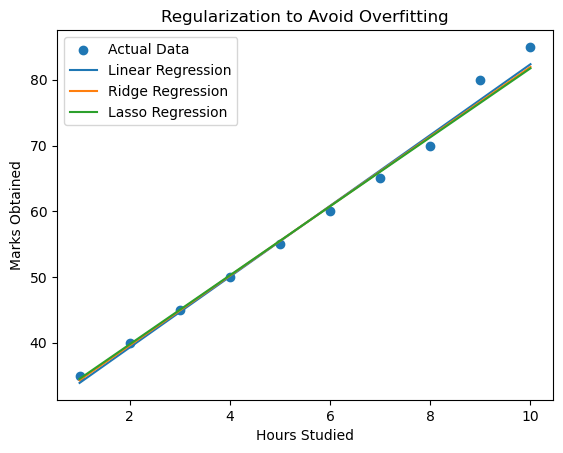

In [15]:
# Visualization
plt.scatter(X, y, label="Actual Data")

plt.plot(X, linear_model.predict(X),
         label="Linear Regression")

plt.plot(X, ridge_model.predict(X),
         label="Ridge Regression")

plt.plot(X, lasso_model.predict(X),
         label="Lasso Regression")

plt.xlabel("Hours Studied")
plt.ylabel("Marks Obtained")
plt.title("Regularization to Avoid Overfitting")
plt.legend()
plt.show()